In [1]:
import pandas as pd

df = pd.read_csv("driver-data.csv")

print(df.head())
print(df.shape)

           id  mean_dist_day  mean_over_speed_perc
0  3423311935          71.24                    28
1  3423313212          52.53                    25
2  3423313724          64.54                    27
3  3423311373          55.69                    22
4  3423310999          54.58                    25
(4000, 3)


In [2]:
X = df[['mean_dist_day', 'mean_over_speed_perc']]

In [3]:
from sklearn.cluster import KMeans

# Create the K-Means clustering model with 2 clusters
kmeans = KMeans(
    n_clusters=2,      # Number of clusters to form
    random_state=42,   # Ensures reproducible results
    n_init=10          # Runs K-Means 10 times with different initial centroids
)

# Train the model on X and assign each data point to a cluster
df['cluster'] = kmeans.fit_predict(X)

In [4]:
print("Centroids:")
print(kmeans.cluster_centers_)

Centroids:
[[ 50.04763437   8.82875   ]
 [180.017075    18.29      ]]


In [5]:
print(df.head(10))

           id  mean_dist_day  mean_over_speed_perc  cluster
0  3423311935          71.24                    28        0
1  3423313212          52.53                    25        0
2  3423313724          64.54                    27        0
3  3423311373          55.69                    22        0
4  3423310999          54.58                    25        0
5  3423313857          41.91                    10        0
6  3423312432          58.64                    20        0
7  3423311434          52.02                     8        0
8  3423311328          31.25                    34        0
9  3423312488          44.31                    19        0


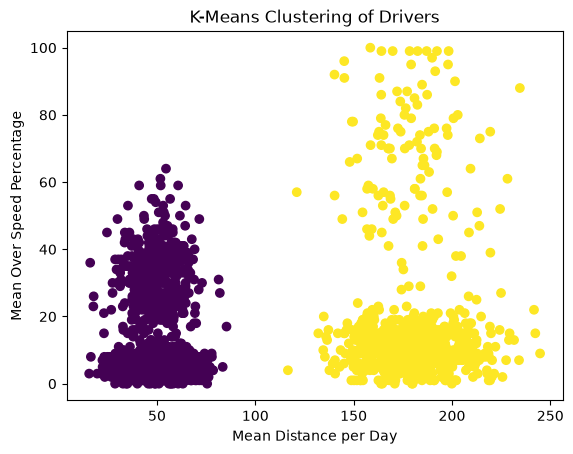

In [6]:
import matplotlib.pyplot as plt

plt.scatter(
    df['mean_dist_day'],
    df['mean_over_speed_perc'],
    c=df['cluster']
)

plt.xlabel("Mean Distance per Day")
plt.ylabel("Mean Over Speed Percentage")
plt.title("K-Means Clustering of Drivers")
plt.show()

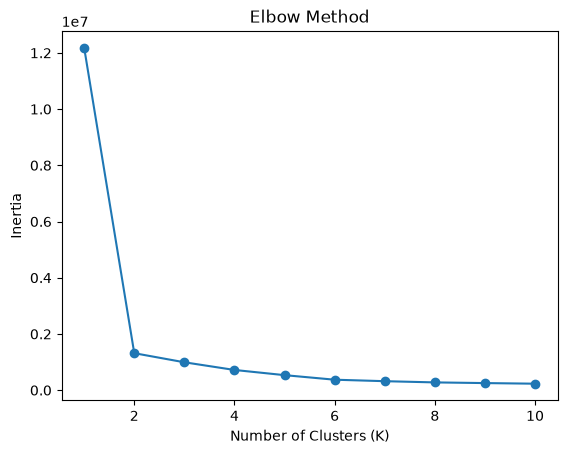

In [7]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

# Store the inertia (within-cluster sum of squares) for each K value
inertia = []

# Try different numbers of clusters from 1 to 10
for k in range(1, 11):

    # Create the K-Means model with k clusters
    kmeans = KMeans(
        n_clusters=k,      # Number of clusters
        random_state=42,   # Ensures reproducible results
        n_init=10          # Runs K-Means 10 times with different initial centroids
    )

    # Fit the model on the dataset
    kmeans.fit(X)

    # Store the inertia value for this K
    inertia.append(kmeans.inertia_)

# Plot K values against their corresponding inertia
plt.plot(range(1, 11), inertia, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

Cluster Centroids:
[[ 49.99263253   5.20447169]
 [180.34311782  10.52011494]
 [177.83509615  70.28846154]
 [ 50.40482436  32.36533958]]


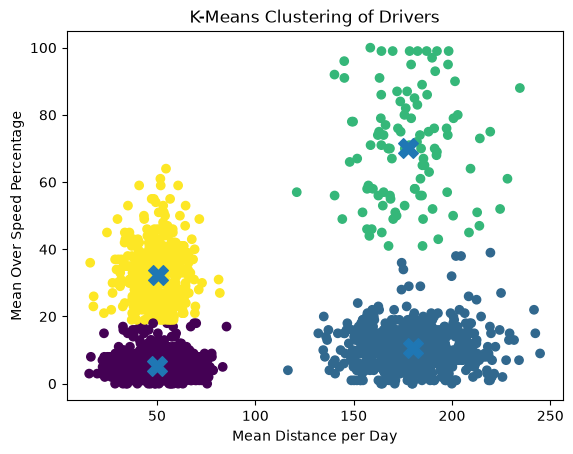

In [13]:
# K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Fit and predict
df['cluster'] = kmeans.fit_predict(X)

# Display centroids
print("Cluster Centroids:")
print(kmeans.cluster_centers_)

# Plot
plt.scatter(
    df['mean_dist_day'],
    df['mean_over_speed_perc'],
    c=df['cluster']
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200
)

plt.xlabel("Mean Distance per Day")
plt.ylabel("Mean Over Speed Percentage")
plt.title("K-Means Clustering of Drivers")
plt.show()

In [11]:
from sklearn.metrics import silhouette_score
#ndicating well-separated and compact clusters and higher the value the better
for k in range(2, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    score = silhouette_score(X, labels)
    print(k, score)

2 0.8490223286225532
3 0.8231396834167266
4 0.5907475009381601
5 0.5120892324508957
6 0.4855556906074069
7 0.46064082858211813
8 0.45025981333234816
9 0.4441021017698188
10 0.43459501657458205


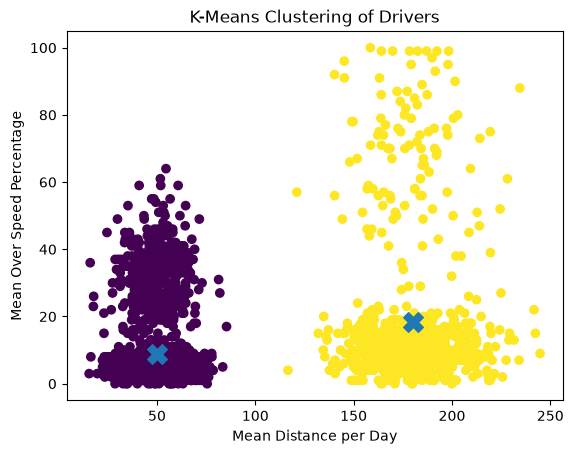

In [14]:
# K-Means
kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

# Fit and predict
df['cluster'] = kmeans.fit_predict(X)

# Plot
plt.scatter(
    df['mean_dist_day'],
    df['mean_over_speed_perc'],
    c=df['cluster']
)

plt.scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker='X',
    s=200
)

plt.xlabel("Mean Distance per Day")
plt.ylabel("Mean Over Speed Percentage")
plt.title("K-Means Clustering of Drivers")
plt.show()